#### Análisis y Procesamiento de Señales

# TS5: Estimación espectral. Ancho de banda de señales reales
#### Juan Martucci

# Análisis y resultados

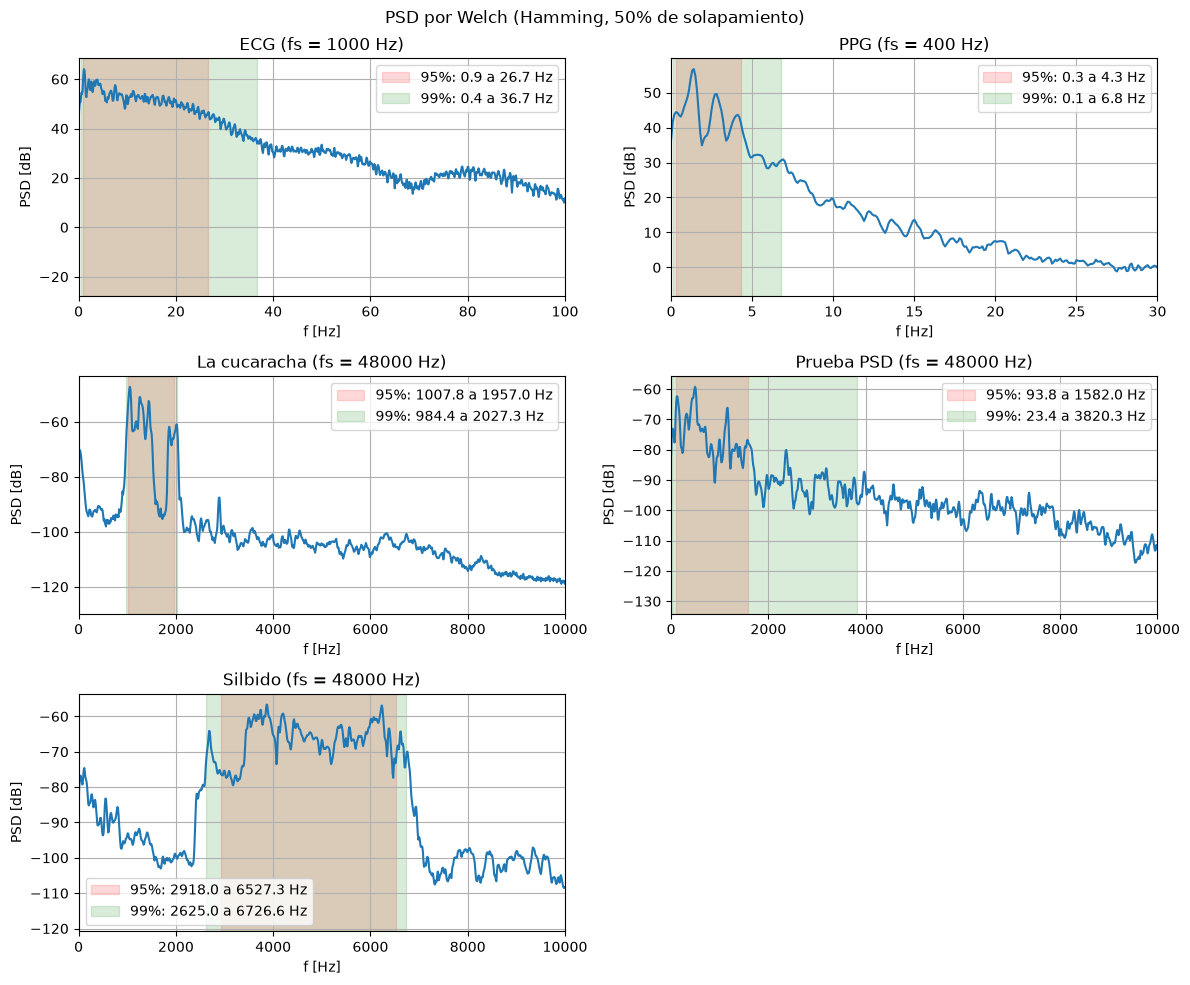

Señal           fs [Hz]   T [s]  pico [Hz]        banda 95% [Hz]     BW 95%        banda 99% [Hz]     BW 99%
ECG                1000    30.0        1.1            0.9 - 26.7       25.8            0.4 - 36.7       36.3
PPG                 400   112.3        1.4             0.3 - 4.3        4.0             0.1 - 6.8        6.7
La cucaracha      48000     3.0     1054.7       1007.8 - 1957.0      949.2        984.4 - 2027.3     1043.0
Prueba PSD        48000     3.0      492.2         93.8 - 1582.0     1488.3         23.4 - 3820.3     3796.9
Silbido           48000     3.0     3867.2       2918.0 - 6527.3     3609.4       2625.0 - 6726.6     4101.6


In [1]:
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
from scipy import signal as sig

import warnings
warnings.filterwarnings('ignore', category=sio.wavfile.WavFileWarning)

# Lectura de las señales (misma forma que en lectura_sigs.py)
# de ECG y PPG uso las versiones sin ruido, que son las que carga lectura_sigs.py

fs_ecg = 1000            # Hz
ecg = np.load('ecg_sin_ruido.npy')

fs_ppg = 400             # Hz
ppg = np.load('ppg_sin_ruido.npy')

fs_cuca, cuca = sio.wavfile.read('la cucaracha.wav')
fs_prueba, prueba = sio.wavfile.read('prueba psd.wav')
fs_silb, silb = sio.wavfile.read('silbido.wav')


# Para cada señal guardo: registro, fs, largo de segmento para Welch y hasta dónde grafico
# ECG y PPG: segmentos de 5 s -> resolución de 1/5 s = 0.2 Hz
# audio: 2048 muestras (~43 ms) -> resolución de 48000/2048 = 23.4 Hz
# nfft = 2*nper no mejora la resolución, solo hace más fina la grilla (0.1 Hz y 11.7 Hz)

senales = {'ECG'         : [ecg, fs_ecg, 5*fs_ecg, 100],
           'PPG'         : [ppg, fs_ppg, 5*fs_ppg, 30],
           'La cucaracha': [cuca, fs_cuca, 2048, 10000],
           'Prueba PSD'  : [prueba, fs_prueba, 2048, 10000],
           'Silbido'     : [silb, fs_silb, 2048, 10000]}

porcs = [0.95, 0.99]
colores = {0.95: 'r', 0.99: 'g'}


# 1) PSD por Welch
# no saco la media a mano porque welch ya se la saca a cada segmento (detrend='constant' por defecto)

def mi_psd_welch(xx, fs, nper, ventana='hamming'):
    ff, pxx = sig.welch(xx, fs=fs, window=ventana, nperseg=nper,
                        noverlap=nper//2, nfft=2*nper)
    return ff, pxx


# 2) Ancho de banda a partir de la potencia acumulada
# busco la banda [f1, f2] que junta el porc de la potencia total,
# dejando afuera (1-porc)/2 por abajo y (1-porc)/2 por arriba

def mi_ancho_banda(ff, pxx, porc=0.95):
    pot_acum = np.cumsum(pxx)/np.sum(pxx)
    idx1 = np.where(pot_acum >= (1 - porc)/2)[0][0]
    idx2 = np.where(pot_acum >= 1 - (1 - porc)/2)[0][0]
    return ff[idx1], ff[idx2]


resultados = {}
picos = {}

fig, axs = plt.subplots(3, 2, figsize=(12, 10))
axs = axs.flatten()

for ii, (nombre, (xx, fs, nper, fmax)) in enumerate(senales.items()):

    ff, pxx = mi_psd_welch(xx, fs, nper)

    # frecuencia donde está el máximo de la PSD
    picos[nombre] = ff[np.argmax(pxx)]

    resultados[nombre] = {}
    for porc in porcs:
        resultados[nombre][porc] = mi_ancho_banda(ff, pxx, porc)

    axs[ii].plot(ff, 10*np.log10(pxx))

    for porc in porcs:
        f1, f2 = resultados[nombre][porc]
        axs[ii].axvspan(f1, f2, color=colores[porc], alpha=0.15,
                        label="{:.0f}%: {:.1f} a {:.1f} Hz".format(100*porc, f1, f2))

    axs[ii].set_xlim(0, fmax)
    axs[ii].set_title("{} (fs = {:d} Hz)".format(nombre, fs))
    axs[ii].set_xlabel("f [Hz]")
    axs[ii].set_ylabel("PSD [dB]")
    axs[ii].legend()
    axs[ii].grid(True)

axs[5].axis('off')

fig.suptitle("PSD por Welch (Hamming, 50% de solapamiento)")
plt.tight_layout()
plt.show()


# Tabla comparativa (T es la duración del registro)

print("{:<14}{:>9}{:>8}{:>11}{:>22}{:>11}{:>22}{:>11}".format("Señal", "fs [Hz]", "T [s]", "pico [Hz]",
                                                              "banda 95% [Hz]", "BW 95%", "banda 99% [Hz]", "BW 99%"))

for nombre, (xx, fs, nper, fmax) in senales.items():
    fila = "{:<14}{:>9d}{:>8.1f}{:>11.1f}".format(nombre, fs, len(xx)/fs, picos[nombre])
    for porc in porcs:
        f1, f2 = resultados[nombre][porc]
        fila += "{:>22}{:>11.1f}".format("{:.1f} - {:.1f}".format(f1, f2), f2 - f1)
    print(fila)


## Conclusiones

Para estimar la PSD usé el método de Welch con ventana Hamming y 50% de solapamiento. Lo elegí sobre el periodograma ventaneado porque promediando segmentos la varianza baja mucho, y los registros alcanzan para tener varios segmentos: con las duraciones de la tabla quedan 11 segmentos en el ECG, 43 en el PPG y 139 en cada audio. De ECG y PPG usé las versiones sin ruido, que son las que carga `lectura_sigs.py`.

El largo del segmento lo elegí distinto para cada tipo de señal. En ECG y PPG usé 5 s, que da una resolución de 0.2 Hz. La información está en unos pocos Hz, y con segmentos más cortos el pico de la frecuencia cardíaca se ensancha y se mezcla con lo que está por debajo. En audio usé 2048 muestras (~43 ms, unos 23 Hz de resolución), que alcanza para ver los picos de los silbidos y de la voz y deja muchos segmentos para promediar. En todas puse nfft = 2·nper, que no mejora la resolución pero hace más fina la grilla de frecuencias, y así los bordes de la banda quedan mejor ubicados. No hizo falta sacar la media a mano porque `welch` ya se la saca a cada segmento.

Para el ancho de banda usé la potencia acumulada: busqué la banda $[f_1, f_2]$ que junta el 95% (y el 99%) de la potencia, dejando afuera la mitad del resto de cada lado. Al principio lo había calculado desde 0 Hz hasta donde se acumulaba el 95%, pero con el silbido eso daba unos 6.3 kHz de ancho de banda para una señal que casi no tiene potencia debajo de 2.5 kHz, así que me quedé con la banda entre dos frecuencias.

En el ECG el pico más alto está en 1.1 Hz, que corresponde a 66 latidos por minuto. La PSD cae de a poco, sin un corte claro, y por eso el resultado depende bastante del porcentaje que se pida: la banda llega a 26.7 Hz para el 95% y a 36.7 Hz para el 99%. Lo que queda afuera son los detalles más rápidos del complejo QRS, que son los que hacen falta si se quiere conservar bien la forma del latido.

El PPG es la señal más angosta, entre 0.3 y 4.3 Hz al 95%. El pico principal está en 1.4 Hz (84 latidos por minuto) y se ven también el segundo y el tercer armónico, cerca de 2.8 y 4.2 Hz. El borde del 95% queda justo después del tercer armónico, y para llegar al 99% hay que sumar lo que viene más arriba, que tiene poca potencia pero se extiende hasta casi 7 Hz. Es más angosta que el ECG porque la onda de pulso es mucho más suave, no tiene nada parecido al QRS.

En los dos silbidos la potencia está concentrada en la banda del silbido y afuera casi no hay nada, por eso el ancho de banda cambia poco entre 95% y 99%. En "La cucaracha" se escuchan notas separadas, y en la PSD aparecen como unos pocos picos entre 1 y 2 kHz. El otro silbido está más arriba, entre 2.9 y 6.5 kHz al 95%, y es bastante más ancho. Al escucharlo no son notas separadas sino un silbido que sube y baja de forma continua, entonces al promediar la potencia queda repartida en toda la banda que recorre y la PSD queda como una meseta en vez de picos. En los dos también hay algo de potencia cerca de 0 Hz, que supongo que es ruido de la grabación, pero es tan poca que no cambia los resultados.

La voz ("Prueba PSD") es la que más cambia según el criterio. Al 95% queda entre 94 y 1582 Hz, que es donde están las vocales: son sonoras, tienen la mayor parte de la potencia y ahí está el pico más alto, en 492 Hz. Pero al 99% la banda llega a 3.8 kHz, más del doble. Esa cola la ponen las consonantes, que son más ruidosas y tienen poca potencia pero repartida en frecuencias altas. Por eso la telefonía puede usar solo de 300 a 3400 Hz: con eso la voz se entiende aunque no se reproduzca completa.

Comparando con las frecuencias de muestreo, todas las señales ocupan mucho menos que $f_s/2$: el ECG usa unos 37 Hz de 500 Hz disponibles y el audio a lo sumo 6.7 kHz de 24 kHz. En la tabla también se ve que el ancho de banda no es un número único de la señal, depende del criterio. En los silbidos pasar del 95% al 99% agranda la banda entre un 10 y un 15%, en ECG y PPG entre un 40 y un 70% (hay que sumar la cola del ECG o lo que está arriba del tercer armónico en el PPG), y en la voz la banda más que se duplica por las consonantes.